In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Chapitre 1: Comprendre le machine learning

Considérons deux variables $y$ et $X$ données par les tableaux suivants:

$y = (y_1, y_2, \dots, y_n)$ et $x = (x_1, x_2, \dots, x_n)$. Notre but est d'établir une rélation entre les deux variables.


In [3]:
data = pd.read_csv("1_regression_lineaire.csv")
data

,x,y
0,7.740,29.505
1,4.389,17.377
2,8.586,30.748
3,6.974,25.594
4,0.942,8.500
...,...,...
195,1.793,10.487
196,5.994,22.038
197,8.746,32.156
198,1.964,12.297


## I - Par la méthode des moindres carrées ordinaires

En passant par la méthode des moindres carrés ordinaires on a :

$$y_{i} = \beta_{0} + \beta_{1}x_{i} + \epsilon_{i}$$

$$\epsilon_{i}^{2} = \left(y_{i} - (\beta_{0} + \beta_{1}x_{i})\right)^{2}$$

$$S(\beta_{0}, \beta_{1}) = \sum_{i=1}^{N}\epsilon_{i}^{2} = \sum_{i=1}^{N}\left(y_{i} - \beta_{0} - \beta_{1}x_{i}\right)^{2}$$

On cherche $(\hat\beta_{0}, \hat\beta_{1})$ qui minimisent $S$. On annule les dérivées partielles.

### Dérivée par rapport à $\beta_{0}$

$$\frac{\partial S}{\partial \beta_{0}} = -2\sum_{i=1}^{N}\left(y_{i} - \beta_{0} - \beta_{1}x_{i}\right) = 0$$

$$\sum_{i=1}^{N}y_{i} = N\beta_{0} + \beta_{1}\sum_{i=1}^{N}x_{i}$$

En divisant par $N$ (avec $\bar{x}$ et $\bar{y}$ les moyennes) :

$$\boxed{\hat\beta_{0} = \bar{y} - \hat\beta_{1}\bar{x}}$$

### Dérivée par rapport à $\beta_{1}$

$$\frac{\partial S}{\partial \beta_{1}} = -2\sum_{i=1}^{N}x_{i}\left(y_{i} - \beta_{0} - \beta_{1}x_{i}\right) = 0$$

$$\sum_{i=1}^{N}x_{i}y_{i} = \beta_{0}\sum_{i=1}^{N}x_{i} + \beta_{1}\sum_{i=1}^{N}x_{i}^{2}$$

On remplace $\beta_{0}$ par $\bar{y} - \beta_{1}\bar{x}$, avec $\sum x_{i} = N\bar{x}$ :

$$\sum_{i=1}^{N}x_{i}y_{i} = (\bar{y} - \beta_{1}\bar{x})N\bar{x} + \beta_{1}\sum_{i=1}^{N}x_{i}^{2}$$

$$\sum_{i=1}^{N}x_{i}y_{i} - N\bar{x}\bar{y} = \beta_{1}\left(\sum_{i=1}^{N}x_{i}^{2} - N\bar{x}^{2}\right)$$

Or $\sum x_{i}y_{i} - N\bar{x}\bar{y} = \sum (x_{i}-\bar{x})(y_{i}-\bar{y})$ et $\sum x_{i}^{2} - N\bar{x}^{2} = \sum (x_{i}-\bar{x})^{2}$, d'où :

$$\boxed{\hat\beta_{1} = \frac{\sum_{i=1}^{N}(x_{i}-\bar{x})(y_{i}-\bar{y})}{\sum_{i=1}^{N}(x_{i}-\bar{x})^{2}} = \frac{\mathrm{Cov}(x,y)}{\mathrm{Var}(x)}}$$

### Vérification que c'est bien un minimum

La matrice hessienne de $S$ est :

$$H = 2\begin{pmatrix} N & \sum x_{i} \\ \sum x_{i} & \sum x_{i}^{2} \end{pmatrix}$$

Son déterminant vaut :

$$\det H = 4\left(N\sum x_{i}^{2} - \left(\sum x_{i}\right)^{2}\right) = 4N\sum (x_{i}-\bar{x})^{2} > 0$$

et $2N > 0$, donc $H$ est définie positive : le point critique est un minimum (à condition que les $x_{i}$ ne soient pas tous égaux).

### Conclusion

La droite ajustée est :

$$\hat{y} = \hat\beta_{0} + \hat\beta_{1}x$$

Pour `1_regression_lineaire.csv`, on doit retrouver $\hat\beta_{1} \approx 3$ et $\hat\beta_{0} \approx 5$.

In [5]:
data.describe()

,x,y
count,200.000000,200.000000
mean,4.938715,19.848880
std,2.823137,9.065141
min,0.074000,1.522000
25%,2.522500,12.281250
50%,4.790000,20.088500
75%,7.472500,27.931750
max,9.924000,37.779000


In [ ]:
x_bar = data['x'].mean()
y_bar = data['y'].mean()
x_var = data['x'].var()
cov_xy = data[['x', 'y']].cov().iloc[0, 1]
cov_xy

np.float64(24.96093880482412)

In [17]:
beta_1 = cov_xy / x_var
beta_1

np.float64(3.1318222949436545)

In [18]:
beta_0 = y_bar - beta_1 * x_bar
beta_0

np.float64(4.381702254627346)

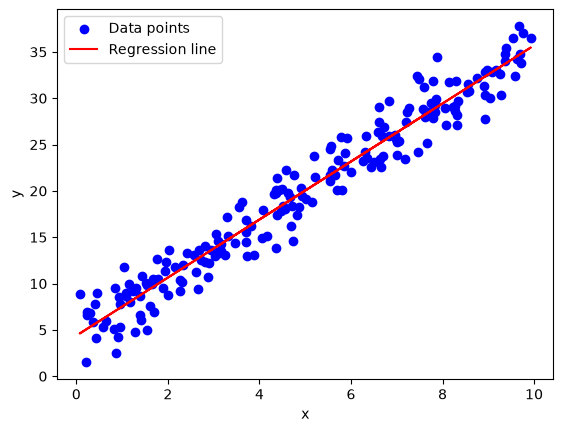

In [21]:
plt.scatter(data['x'], data['y'], color='blue', label='Data points')
plt.plot(data['x'], beta_0 + beta_1 * data['x'], color='red', label='Regression line')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

## II- Par la méthode de la descente de gradient

In [1]:
"""Génère des jeux de données (x, y) pour s'entraîner en machine learning."""
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
N = 200

# 1. Régression linéaire simple : y = 3x + 5 + bruit
x = rng.uniform(0, 10, N)
y = 3 * x + 5 + rng.normal(0, 2, N)
pd.DataFrame({"x": x.round(3), "y": y.round(3)}).to_csv("1_regression_lineaire.csv", index=False)

# 2. Régression polynomiale : y = 0.5x² - 2x + 3 + bruit
x = rng.uniform(-5, 5, N)
y = 0.5 * x**2 - 2 * x + 3 + rng.normal(0, 2, N)
pd.DataFrame({"x": x.round(3), "y": y.round(3)}).to_csv("2_regression_polynomiale.csv", index=False)

# 3. Régression multiple : y = 2*x1 - 1.5*x2 + 0.5*x3 + 10 + bruit
X = rng.normal(0, 1, (N, 3))
y = 2 * X[:, 0] - 1.5 * X[:, 1] + 0.5 * X[:, 2] + 10 + rng.normal(0, 1, N)
df = pd.DataFrame(X.round(3), columns=["x1", "x2", "x3"])
df["y"] = y.round(3)
df.to_csv("3_regression_multiple.csv", index=False)

# 4. Classification binaire : deux nuages de points (y = 0 ou 1)
c0 = rng.normal([2, 2], 1.0, (N // 2, 2))
c1 = rng.normal([5, 5], 1.0, (N // 2, 2))
X = np.vstack([c0, c1])
y = np.array([0] * (N // 2) + [1] * (N // 2))
idx = rng.permutation(N)
df = pd.DataFrame(X[idx].round(3), columns=["x1", "x2"])
df["y"] = y[idx]
df.to_csv("4_classification_binaire.csv", index=False)

# 5. Données avec valeurs aberrantes (outliers) pour tester la robustesse
x = rng.uniform(0, 10, N)
y = 2 * x + 1 + rng.normal(0, 1.5, N)
out = rng.choice(N, 10, replace=False)
y[out] += rng.choice([-1, 1], 10) * rng.uniform(15, 25, 10)
pd.DataFrame({"x": x.round(3), "y": y.round(3)}).to_csv("5_regression_outliers.csv", index=False)

print("OK")

OK


In [2]:
data = pd.read_csv("5_regression_outliers.csv")
data

,x,y
0,5.027,12.764
1,1.518,4.054
2,3.519,4.464
3,5.658,13.091
4,4.134,5.939
...,...,...
195,4.186,11.525
196,3.666,9.164
197,5.214,8.862
198,4.622,9.922
